In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
DATASET_NAME = 'CLEMSON'
RELATIVE_PATH = "C:/Users/tulio/Downloads/Plots/CLEMSON"
CLEMSON_HZ = 15
WINDOW_SIZE = 2
CLEMSON_START = int(WINDOW_SIZE * CLEMSON_HZ * 3)

In [3]:
# Function to normalize columns
def normalize_group(group):
    group[['acc_x', 'acc_y', 'acc_z']] = (group[['acc_x', 'acc_y', 'acc_z']] - group[['acc_x', 'acc_y', 'acc_z']].mean()) / group[['acc_x', 'acc_y', 'acc_z']].std()
    return group

data = pd.read_csv('../../datasets/combined_clemson_cafeteria_data.csv', sep=',')
data = data.groupby('user_id').apply(normalize_group)
data = data.reset_index(drop=True)
data = data.loc[data['activity'].isin(['bite', 'rest', 'drink', 'other'])]
data

C:\Users\tulio\AppData\Local\Temp\ipykernel_21036\1630351706.py:7: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  data = data.groupby('user_id').apply(normalize_group)


,acc_x,acc_y,acc_z,gyr_x,gyr_y,gyr_z,grams,user_id,course,index,activity
0,-3.085055,0.320500,1.546432,65.232882,23.322505,46.738401,828.7,p005,c1,0,other
1,-1.352688,0.644118,1.694550,49.632882,-5.077495,23.938401,828.7,p005,c1,1,other
2,-2.061384,0.666283,1.550435,38.432882,-7.477495,17.938401,828.7,p005,c1,2,other
3,-1.875773,0.555455,1.550435,38.832882,-9.877495,18.738401,828.7,p005,c1,3,other
4,-1.650790,0.608653,1.538426,37.632882,-11.477495,19.138401,828.9,p005,c1,4,other
...,...,...,...,...,...,...,...,...,...,...,...
6367686,1.002465,1.319253,-0.738027,-5.460823,-30.588564,4.409891,826.2,p413,c1,17222,other
6367687,1.292542,1.319253,-0.794112,-5.060823,-19.388564,4.809891,826.3,p413,c1,17223,other
6367688,1.135212,1.482703,-0.797228,-12.660823,-12.988564,0.809891,826.3,p413,c1,17224,other
6367689,1.194211,1.610620,-0.903167,-10.260823,-14.188564,1.209891,826.3,p413,c1,17225,other


In [4]:
data[['x_maf', 'y_maf', 'z_maf']] = data.groupby('user_id')[['acc_x', 'acc_y', 'acc_z']].rolling(window=CLEMSON_HZ).mean().reset_index(drop=True)
data[['x_ema', 'y_ema', 'z_ema']] = data.groupby('user_id')[['acc_x', 'acc_y', 'acc_z']].ewm(span=1.5*CLEMSON_HZ, adjust=False).mean().reset_index(drop=True)

In [5]:
# Class Distribution
print("\nClass Distribution:")
class_counts = data['activity'].value_counts()
total_counts = class_counts.sum()
class_percentages = (class_counts / total_counts) * 100
print(class_counts)


Class Distribution:
activity
other    2314813
rest     1731642
bite      662904
drink     192167
Name: count, dtype: int64


C:\Users\tulio\AppData\Local\Temp\ipykernel_21036\83324950.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=class_counts.index, y=class_percentages, palette='viridis')


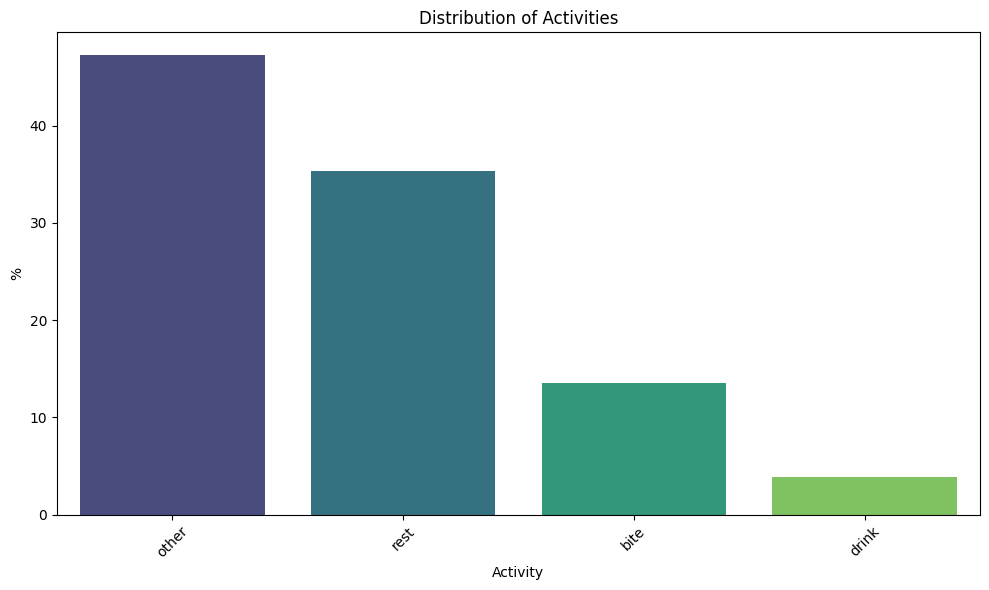

In [6]:
# Plot the class distribution
plt.figure(figsize=(10, 6))
sns.barplot(x=class_counts.index, y=class_percentages, palette='viridis')
plt.title('Distribution of Activities')
plt.xlabel('Activity')
plt.ylabel('%')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()